[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/HumbertoDiego/AjustamentoBasicoIME/blob/main/07_modelos.ipynb)

# Ajustamento Básico - Modelos clássicos de ajustamento

**Maj Diego - 2° Semestre / 2026**

**Objetivos:**

1. Revisar o Modelo Paramétrico

**Referência:** Camil Gemael, Alvaro Muriel Lima Machado, Romualdo Wandresen (2015). *Introdução ao Ajustamento de Observações: Aplicações Geodésicas*. 2ª Ed., Curitiba, Ed. UFPR. $\rightarrow$ **Cap 8, 9 e 10**

## O Problema

Até aqui, o método dos mínimos quadrados (MMQ) foi sempre aplicado a um caso particular: as observações escritas explicitamente como função dos parâmetros desconhecidos, $F(X_a)=L_b$, o **Modelo Paramétrico**.

Esse, no entanto, é só um caso dentre três situações possíveis, que diferem em **o que aparece como incógnita** na equação de ajustamento:

| $\begin{matrix}\text{Situação}\end{matrix}$ | $\begin{matrix}\text{Equação}\end{matrix}$ | $\begin{matrix}\text{Modelo}\end{matrix}$ |
|---|---|---|
| As observações ajustadas podem ser escritas em função de parâmetros | $F(X_a) = L_a$ | **Paramétrico** |
| Não há parâmetros explícitos; as próprias observações ajustadas devem satisfazer uma condição geométrica/física | $F(L_a) = 0$ | **Condicionado/Correlatos** |
| Parâmetros e observações ajustadas aparecem juntos, sem que seja possível isolar um em função do outro | $F(X_a, L_a) = 0$ | **Combinado/Geral/Implícito** |

## 1. Revisar o Modelo Paramétrico

No **Modelo Paramétrico**, <b style="color:#2ECC40">cada observação é modelada como função de parâmetros desconhecidos</b>. 

É o modelo natural quando se deseja estimar grandezas como coordenadas, alturas, coeficientes de uma reta, parâmetros de transformação ou qualquer conjunto de incógnitas que explique as observações.

### **1.1 Modelo Paramétrico - checagem da linearidade**

Quanto à linearidade de $F(X_a) = L_b$:

- $F(X) = F(x_1) = \cos x_2 + 30x_1$ → **linear** em $x_1$
- $F(X) = F(x_1,x_2) = \cos x_2 + 30x_1$ → **não linear** (pois $x_2$ aparece dentro do cosseno)

### **1.2 Modelo Paramétrico - caso linear - solução**


$$
F(X) = L_b \quad\Rightarrow\quad AX = L_b + V
$$

- $A$: matriz *design* $(m\times n)$ dos coeficientes dos parâmetros
- $X$: vetor $(n\times 1)$ dos parâmetros (incógnitas)
- $L_b$: vetor $(m\times 1)$ das observações originais
- $L_a$: vetor $(m\times 1)$ das observações ajustadas
- $V$: vetor $(m\times 1)$ dos resíduos

Buscar a MVC das observações $\Sigma_{L_b}$, arbitrar a variância a priori $\sigma_0^2$, definir a matriz de pesos $P=\sigma_0^2\Sigma_{L_b}^{-1}$ e, com isso, a solução por MMQ fica:

$$
N = A^TPA, \qquad U = A^TPL_b, \qquad X_a = N^{-1}U
$$

$$
L_a = AX_a, \qquad V = L_a - L_b
$$

### **1.3 Modelo Paramétrico - caso linear - checagem da qualidade**

**Variância da unidade de peso a posteriori:**

$$
\hat\sigma_0^2 = \frac{V^TPV}{m-n}
$$

**MVC dos parâmetros ajustados** (se aprovado no teste Qui-Quadrado):

$$
\Sigma_{X_a} = \hat\sigma_0^2\,(A^TPA)^{-1} = \hat\sigma_0^2 N^{-1}
$$

**MVC das observações ajustadas:**

$$
\Sigma_{L_a} = \hat\sigma_0^2\,AN^{-1}A^T
$$

### **1.4 Modelo Paramétrico - caso não linear - solução**

Quando $F$ não pode ser escrita como combinação linear dos parâmetros, aplicamos o **Método de Gauss-Newton** com linearização por série de Taylor de 1ª ordem.

$$
F(X_a) = L_b, \qquad X_a = X_0 + \underbrace{X}_{incremento}, \qquad L_a = L_b + V
$$

Sendo $J$ a matriz jacobiana de $F$ e $J_0 = J(X_0)$:

$$
F(X_0) + J_0 X \approx L_b \quad\Rightarrow\quad J_0 X = L_b - F(X_0) = K \quad \text{lembra de } AX=L \text{?}
$$

**Algoritmo (Método de Gauss-Newton):**

1. Escrever a jacobiana $J$ de $F$ e escolher uma aproximação inicial $X_0$;
3. Repetir até convergência:
   - calcular $J_0 = J(X_0)$, $F(X_0)$ e $K = L_b - F(X_0)$;
   - resolver $J_0 X = K$ pelo MMQ: $X = (J_0^TPJ_0)^{-1}J_0^TPK$;
   - atualizar $X_0 \leftarrow X_0 + X$ (note: $L_b$ **não** é atualizado).

**Critérios de parada:** número máximo de iterações, estabilização de $V^TPV$, ou correção máxima $|X|_{max}$ abaixo de um limiar.



### **1.5 Modelo Paramétrico - caso não linear - checagem da qualidade**

**MVC dos parâmetros:** agora $N = J_0^TPJ_0$ (no lugar de $A^TPA$); com a jacobiana avaliada em $X_0$ que para a última iteração, é considerado parâmetros ajustados, ou seja $J_0 = J(X_a)$; o restante do raciocínio é análogo ao caso linear.

## Lista de exercícios complementares

**Exercício 01** (**Exercício 8.9.1 do Gemael**) (voltaremos a ele na aula sobre **Modelo Condicionado e Combinado** mais adiante): 
- **a)** Identificar parâmetros e ajustá-los pelo **Método Paramétrico**
- **b)** Obter as observações ajustadas e o erro total
- **c)** Avaliar a qualidade do ajustamento

<center><img src="media/imgs/GemaelProblem 8.9.1.png" width="600px"></center>


**Exercício 02** Resolver o sistema não linear sem auxílio de computador:

$$
\begin{cases}
F_1 = x_1+x_2-2x_2^2=-4\\
F_2 = x_1^2+x_2^2=8\\
F_3 = 3x_1^2-x_2^2=7{,}7
\end{cases}
$$

Gabarito: $x_1=1{,}98$ e $x_2=2{,}00$.

**Exercício 03** Dadas as coordenadas observadas de 4 pontos, deseja-se estimar a circunferência (centro $X_C, Y_C$ e raio $r$) que melhor se ajusta a eles 

$F_n(X_a) = (X_n - X_C)^2 + (Y_n - Y_C)^2 - r^2 = L_a, \quad n=1,\dots,4$

| Pontos | X (m) | $\sigma_X^2(m^2)$ | Y (m) | $\sigma_Y^2(m^2)$ |
| :---: | :---: | :---: | :---: | :---: |
| P1 | 150 | 2 | 60 | 2 |
| P2 | 209 | 4 | 100 | 4 |
| P3 | 204 | 2 | 150 | 2 |
| P4 | 150 | 4 | 180 | 4 |

Este é um problema clássico do **Modelo Combinado**, momento em que retornaremos a ele, por enquanto, resolva pelo **Modelo paramétrico**.

Gabarito: $X_C=152$ , $Y_C=120$ e $r=60$.

#### Solução Exercício 03

1) Sistema de equações paramétrico $F(X)=L$:

$
\begin{cases}
F_1 = (150-X_C)^2 + (60-Y_C)^2 - r^2= 0 \\
F_2 = (209-X_C)^2 + (100-Y_C)^2 - r^2= 0 \\
F_3 = (204-X_C)^2 + (150-Y_C)^2 - r^2= 0 \\
F_4 = (150-X_C)^2 + (180-Y_C)^2 - r^2= 0 \\
\end{cases}
$

Onde $L = [0 \ \ 0 \ \ 0 \ \ 0]^T $ , $X = [X_C \ \ Y_C \ \ r]^T$. Os pesos ficarão de fora pois não se encaixam nesta modelagem, assim $P=I$.

2) Jacobiana:

In [75]:
import numpy as np
import sympy as sp 

Xc, Yc, r = sp.symbols('X_c Y_c r')
F1 = (150 - Xc)**2 + (60-Yc)**2 - r**2
F2 = (209 - Xc)**2 + (100-Yc)**2 - r**2
F3 = (204 - Xc)**2 + (150-Yc)**2 - r**2
F4 = (150 - Xc)**2 + (180-Yc)**2 - r**2
F = sp.Matrix([[F1],
               [F2],
               [F3],
               [F4]])
J = F.jacobian(sp.Matrix([Xc, Yc, r]))
J

Matrix([
[2*X_c - 300, 2*Y_c - 120, -2*r],
[2*X_c - 418, 2*Y_c - 200, -2*r],
[2*X_c - 408, 2*Y_c - 300, -2*r],
[2*X_c - 300, 2*Y_c - 360, -2*r]])

3. Chute inicial $X_0$:

- Critério: centro dos pontos na circuferência e raio igual a solução da 1ª equação ($F1$) para este centro.

In [76]:
X0 = [[(150+209+204+150)/4] , [(60+100+150+180)/4], [list(sp.roots( F1.subs({Xc: (150+209+204+150)/4, Yc: (60+100+150+180)/4}), r ).keys())[1]]]
X_0 = np.array(X0, dtype=float)
X_0

array([[178.25      ],
       [122.5       ],
       [ 68.58799093]])

4. Solução:

DeltaX:
 [[-26.03097378]
 [ -2.56380491]
 [-13.00792585]]
Erro:
 29.212853788552273 

Xa:
 [[152.21902622]
 [119.93619509]
 [ 55.58006508]]
DeltaX:
 [[-1.33226763e-15]
 [ 2.22044605e-15]
 [ 4.63276317e+00]]
Erro:
 4.632763168108924 

Xa:
 [[152.21902622]
 [119.93619509]
 [ 60.21282825]]
DeltaX:
 [[-6.24500451e-17]
 [ 2.01921813e-15]
 [-1.78221944e-01]]
Erro:
 0.1782219436831768 

Xa:
 [[152.21902622]
 [119.93619509]
 [ 60.03460631]]
DeltaX:
 [[ 5.55111512e-17]
 [ 2.01227923e-15]
 [-2.64539598e-04]]
Erro:
 0.00026453959776546326 

Xa:
 [[152.21902622]
 [119.93619509]
 [ 60.03434177]]
DeltaX:
 [[-2.08166817e-17]
 [ 2.01227923e-15]
 [-5.82843974e-10]]
Erro:
 5.828439744760873e-10 <<<-------------- erro<=10e-6 (FIM)

Xa:
 [[152.21902622]
 [119.93619509]
 [ 60.03434177]]


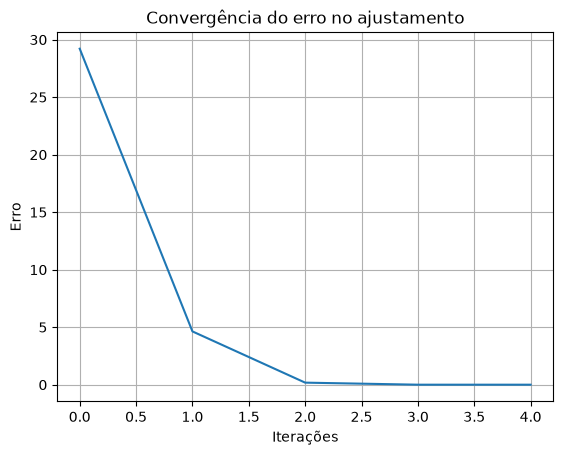

In [77]:
import matplotlib.pyplot as plt 

# mount Lb
Lb = np.array([[0],
               [0],
               [0],
               [0]], dtype=float)
# mount X_0
X_0 = np.array(X0, dtype=float)

### Início do ajustametno 
erros = [] # guardar cada erro durante as iterações para compor um gráfico
erro = 10000000
while erro>10e-6:
    # update L0 = F(X0)
    L0 = np.array(F.subs({Xc: X_0[0][0], Yc: X_0[1][0], r: X_0[2][0]}).evalf().tolist(), dtype=float)
    # update L
    L = L0 - Lb
    # update J
    J0 = np.array(J.subs({Xc: X_0[0][0], Yc: X_0[1][0], r: X_0[2][0]}).evalf().tolist(), dtype=float)
    # update X = vetor das correções
    DeltaX = - np.linalg.inv(J0.T @ J0) @ J0.T @ L
    DeltaX = DeltaX
    print("DeltaX:\n", DeltaX)
    # update erro
    erro = np.linalg.norm(DeltaX)
    erros.append(erro)
    flag = "" if erro>10e-6 else "<<<-------------- erro<=10e-6 (FIM)"
    print("Erro:\n", erro, flag)
    # update X_0
    X_0 = DeltaX + X_0
    print("\nXa:\n", X_0)

# Gráfico
plt.title("Convergência do erro no ajustamento")
plt.xlabel("Iterações")
plt.ylabel("Erro")
plt.grid()
plt.plot(erros)
plt.show()

5. Observações ajustadas

In [80]:
L0 = np.array(F.subs({Xc: X_0[0][0], Yc: X_0[1][0], r: X_0[2][0]}).evalf().tolist(), dtype=float)
L0

array([[ -6.85063266],
       [ 17.40866652],
       [-19.02058009],
       [  8.46254623]])